In [7]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

best_model = joblib.load("../models/best_model.joblib")

In [5]:
df = pd.read_csv("../data/players_features.csv")

y = np.log1p(df["market_value_in_eur"])
X = df.drop(columns=["player_id", "name", "market_value_in_eur"])

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
pred_log = best_model.predict(X_test)

rmse_log = np.sqrt(mean_squared_error(y_test, pred_log))
mae_log = mean_absolute_error(y_test, pred_log)
r2_log = r2_score(y_test, pred_log)

y_true_eur = np.expm1(y_test)
y_pred_eur = np.expm1(pred_log)
mae_eur = mean_absolute_error(y_true_eur, y_pred_eur)

print(f"RMSE (log): {rmse_log:.3f}")
print(f"MAE (log): {mae_log:.3f}")
print(f"R2 (log): {r2_log:.3f}")
print(f"MAE (EUR): {mae_eur:,.0f}")

RMSE (log): 0.820
MAE (log): 0.624
R2 (log): 0.736
MAE (EUR): 1,417,827


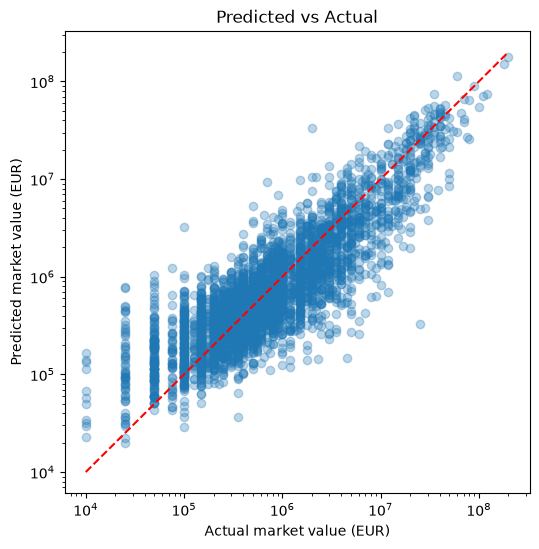

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y_true_eur, y_pred_eur, alpha=0.3)
lim = [y_true_eur.min(), y_true_eur.max()]
plt.plot(lim, lim, "r--")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Actual market value (EUR)")
plt.ylabel("Predicted market value (EUR)")
plt.title("Predicted vs Actual")
plt.savefig("../images/pred_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

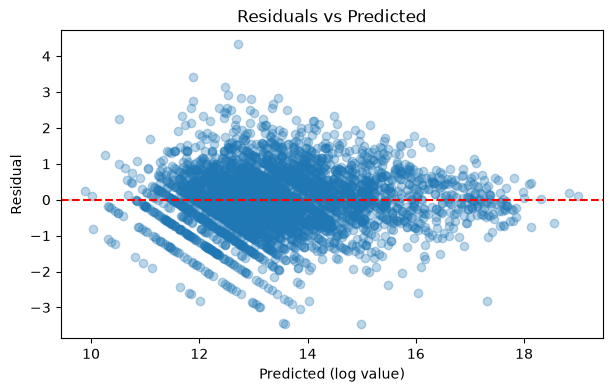

In [11]:
residuals = y_test - pred_log

plt.figure(figsize=(7, 4))
plt.scatter(pred_log, residuals, alpha=0.3)
plt.axhline(0, color="r", linestyle="--")
plt.xlabel("Predicted (log value)")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted")
plt.savefig("../images/residuals.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
errors = pd.DataFrame({"actual": y_true_eur.values, "predicted": y_pred_eur})
errors["abs_error"] = (errors["actual"] - errors["predicted"]).abs()
errors["bucket"] = pd.qcut(errors["actual"], 5, duplicates="drop")

print(errors.groupby("bucket", observed=True)["abs_error"].agg(["mean", "median", "count"]))

                                  mean        median  count
bucket                                                     
(9999.999, 200000.0]      1.532462e+05  8.290902e+04    831
(200000.0, 400000.0]      1.798162e+05  1.127460e+05    666
(400000.0, 900000.0]      3.753431e+05  2.378161e+05    730
(900000.0, 3000000.0]     9.618333e+05  7.276444e+05    808
(3000000.0, 200000000.0]  6.069282e+06  3.536981e+06    646


In [13]:
errors["pct_error"] = errors["abs_error"] / errors["actual"] * 100

print(errors.groupby("bucket", observed=True)["pct_error"].agg(["mean", "median"]).round(1))

                           mean  median
bucket                                 
(9999.999, 200000.0]      183.3    81.2
(200000.0, 400000.0]       55.7    36.4
(400000.0, 900000.0]       58.0    37.9
(900000.0, 3000000.0]      54.0    47.4
(3000000.0, 200000000.0]   49.9    47.0


In [14]:
import json

schema = {}
for col in X_train.columns:
    if pd.api.types.is_numeric_dtype(X_train[col]):
        schema[col] = {
            "type": "numeric",
            "min": float(X_train[col].min()),
            "max": float(X_train[col].max()),
            "default": float(X_train[col].median()),
        }
    else:
        cats = sorted(X_train[col].dropna().astype(str).unique().tolist())
        schema[col] = {"type": "categorical", "options": cats}

with open("../models/feature_schema.json", "w") as f:
    json.dump(schema, f, indent=2)

print(len(schema), "features saved")

22 features saved


In [15]:
print(X_train.dtypes)

country_of_citizenship                      str
sub_position                                str
position                                    str
foot                                        str
height_in_cm                            float64
international_caps                      float64
international_goals                     float64
current_club_domestic_competition_id        str
caps_missing                              int64
age                                     float64
contract_months_left                    float64
no_league                                 int64
has_contract_info                         int64
games                                   float64
minutes                                 float64
goals                                   float64
assists                                 float64
yellow                                  float64
red                                     float64
goals_per90                             float64
assists_per90                           